# Proyek Analisis Data: Air Quality Dataset
- **Nama:** Pramaisi Afra
- **Email:** pramaisiafram@gmail.com
- **ID Dicoding:** Pramaisi Afra 

## Pertanyaan Bisnis

- **Pertanyaan 1:** Stasiun pemantauan mana yang memiliki rata-rata konsentrasi PM2.5 tertinggi dan terendah di Beijing selama periode Maret 2013 – Februari 2017, dan berapa selisihnya (µg/m³)?
- **Pertanyaan 2:** Pada musim dan bulan apa rata-rata konsentrasi PM2.5 di Beijing mencapai level tertinggi selama periode Maret 2013 – Februari 2017, dan berapa persen lebih tinggi dibandingkan musim dengan rata-rata terendah?

## Import Library

In [1]:
import glob

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## Data Wrangling

### Gathering Data

Dataset 12 file CSV, digabung menjadi satu DataFrame.

In [2]:
files = sorted(glob.glob("data/PRSA_Data_*.csv"))
df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
print(f"Jumlah file: {len(files)}")
df.head()

Jumlah file: 12


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


In [3]:
df.shape

(420768, 18)

**Insight:**
- Data berasal dari 12 stasiun dan berhasil digabung menjadi 420.768 baris dan 18 kolom.
- Data berisi pengukuran per jam dari 1 Maret 2013 sampai 28 Februari 2017, meliputi polutan (PM2.5, PM10, SO2, NO2, CO, O3) dan kondisi cuaca (TEMP, PRES, DEWP, RAIN, wd, WSPM).

### Assessing Data

Memeriksa tipe data, missing value, duplikasi, dan outlier.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    412029 non-null  float64
 6   PM10     414319 non-null  float64
 7   SO2      411747 non-null  float64
 8   NO2      408652 non-null  float64
 9   CO       400067 non-null  float64
 10  O3       407491 non-null  float64
 11  TEMP     420370 non-null  float64
 12  PRES     420375 non-null  float64
 13  DEWP     420365 non-null  float64
 14  RAIN     420378 non-null  float64
 15  wd       418946 non-null  str    
 16  WSPM     420450 non-null  float64
 17  station  420768 non-null  str    
dtypes: float64(11), int64(5), str(2)
memory usage: 62.1 MB


In [5]:
df.isna().sum()

No             0
year           0
month          0
day            0
hour           0
PM2.5       8739
PM10        6449
SO2         9021
NO2        12116
CO         20701
O3         13277
TEMP         398
PRES         393
DEWP         403
RAIN         390
wd          1822
WSPM         318
station        0
dtype: int64

In [6]:
print("Jumlah baris duplikat:", df.duplicated().sum())
print("Duplikat (waktu + stasiun):", df.duplicated(subset=["year", "month", "day", "hour", "station"]).sum())

Jumlah baris duplikat: 0
Duplikat (waktu + stasiun): 0


In [7]:
df.describe()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
count,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,412029.000000,414319.000000,411747.000000,408652.000000,400067.000000,407491.000000,420370.000000,420375.000000,420365.000000,420378.000000,420450.000000
mean,17532.500000,2014.662560,6.522930,15.729637,11.500000,79.793428,104.602618,15.830835,50.638586,1230.766454,57.372271,13.538976,1010.746982,2.490822,0.064476,1.729711
std,10122.116943,1.177198,3.448707,8.800102,6.922195,80.822391,91.772426,21.650603,35.127912,1160.182716,56.661607,11.436139,10.474055,13.793847,0.821004,1.246386
min,1.000000,2013.000000,1.000000,1.000000,0.000000,2.000000,2.000000,0.285600,1.026500,100.000000,0.214200,-19.900000,982.400000,-43.400000,0.000000,0.000000
25%,8766.750000,2014.000000,4.000000,8.000000,5.750000,20.000000,36.000000,3.000000,23.000000,500.000000,11.000000,3.100000,1002.300000,-8.900000,0.000000,0.900000
50%,17532.500000,2015.000000,7.000000,16.000000,11.500000,55.000000,82.000000,7.000000,43.000000,900.000000,45.000000,14.500000,1010.400000,3.100000,0.000000,1.400000
75%,26298.250000,2016.000000,10.000000,23.000000,17.250000,111.000000,145.000000,20.000000,71.000000,1500.000000,82.000000,23.300000,1019.000000,15.100000,0.000000,2.200000
max,35064.000000,2017.000000,12.000000,31.000000,23.000000,999.000000,999.000000,500.000000,290.000000,10000.000000,1071.000000,41.600000,1042.800000,29.100000,72.500000,13.200000


In [8]:
q1, q3 = df["PM2.5"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print(f"Batas atas IQR PM2.5: {upper:.1f}")
print("Jumlah outlier PM2.5:", (df["PM2.5"] > upper).sum())

Batas atas IQR PM2.5: 247.5
Jumlah outlier PM2.5: 19142


**Insight:**
- Missing value: hampir semua kolom polutan dan cuaca memiliki nilai kosong (contoh: PM2.5 8.739 baris, CO 20.701 baris, wd 1.822 baris). Solusi: isi nilai numerik dengan data time series sehingga nilai sebelum/sesudah relevan, dan kolom kategori `wd` dengan forward/backward fill per stasiun.
- Tipe data waktu: informasi waktu terpecah di kolom `year`, `month`, `day`, `hour` dan tidak ada kolom bertipe datetime. Solusi: buat kolom `datetime`.
- Outlier: ada 19.142 nilai PM2.5 di atas batas IQR (maks 999 µg/m³). Nilai ini **tidak dihapus** karena kemungkinan lonjakan polusi saat kabut asap/smog di Beijing memang terjadi dan penting untuk insigght analisis.
- Tidak ada data duplikat.
- Kolom `No` hanya nomor urut dan tidak dibutuhkan.

### Cleaning Data

In [9]:
df["datetime"] = pd.to_datetime(df[["year", "month", "day", "hour"]])
df = df.drop(columns="No")

num_cols = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
df[num_cols] = df.groupby("station")[num_cols].transform(
    lambda s: s.interpolate(limit_direction="both")
)
df["wd"] = df.groupby("station")["wd"].transform(lambda s: s.ffill().bfill())

df.isna().sum()

year        0
month       0
day         0
hour        0
PM2.5       0
PM10        0
SO2         0
NO2         0
CO          0
O3          0
TEMP        0
PRES        0
DEWP        0
RAIN        0
wd          0
WSPM        0
station     0
datetime    0
dtype: int64

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   year      420768 non-null  int64         
 1   month     420768 non-null  int64         
 2   day       420768 non-null  int64         
 3   hour      420768 non-null  int64         
 4   PM2.5     420768 non-null  float64       
 5   PM10      420768 non-null  float64       
 6   SO2       420768 non-null  float64       
 7   NO2       420768 non-null  float64       
 8   CO        420768 non-null  float64       
 9   O3        420768 non-null  float64       
 10  TEMP      420768 non-null  float64       
 11  PRES      420768 non-null  float64       
 12  DEWP      420768 non-null  float64       
 13  RAIN      420768 non-null  float64       
 14  wd        420768 non-null  str           
 15  WSPM      420768 non-null  float64       
 16  station   420768 non-null  str           
 17  da

**Insight:**
- Semua missing value sudah terisi.
- Kolom `datetime` bertipe `datetime64` sudah di build.
- Outlier dipertahankan karena merupakan kejadian polusi nyata.

## Exploratory Data Analysis (EDA)

### Explore statistik umum

In [11]:
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
PM2.5,420768.0,79.839718,80.950217,2.0000,20.0,55.0,111.0,999.0
PM10,420768.0,104.910268,92.431422,2.0000,36.0,82.0,145.0,999.0
SO2,420768.0,15.913090,21.896609,0.2856,3.0,7.0,20.0,500.0
NO2,420768.0,50.599018,35.171921,1.0265,23.0,43.0,71.0,290.0
CO,420768.0,1235.682649,1161.790893,100.0000,500.0,900.0,1500.0,10000.0
O3,420768.0,57.237872,57.135195,0.2142,10.0,44.0,82.0,1071.0
TEMP,420768.0,13.531692,11.437867,-19.9000,3.1,14.5,23.3,41.6
PRES,420768.0,1010.753337,10.474302,982.4000,1002.3,1010.4,1019.0,1042.8
DEWP,420768.0,2.482421,13.797675,-43.4000,-8.9,3.0,15.1,29.1
RAIN,420768.0,0.064428,0.820638,0.0000,0.0,0.0,0.0,72.5


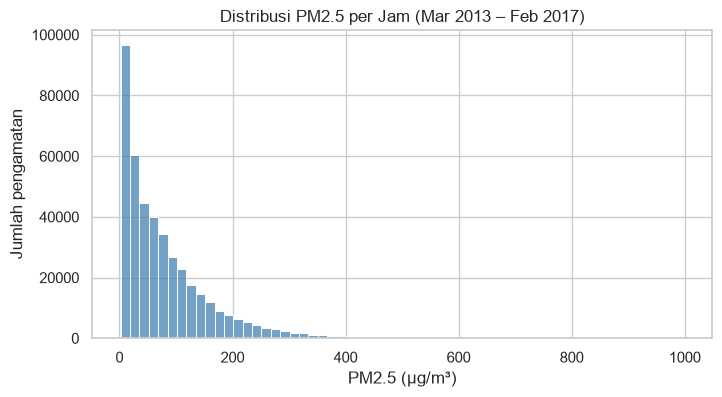

In [12]:
plt.figure(figsize=(8, 4))
sns.histplot(df["PM2.5"], bins=60, color="steelblue")
plt.title("Distribusi PM2.5 per Jam (Mar 2013 – Feb 2017)")
plt.xlabel("PM2.5 (µg/m³)")
plt.ylabel("Jumlah pengamatan")
plt.show()

### Explore PM2.5 per stasiun (Pertanyaan 1)

In [13]:
station_pm25 = df.groupby("station")["PM2.5"].agg(["mean", "median", "max"]).sort_values("mean", ascending=False)
station_pm25.round(2)

,mean,median,max
station,,,
Dongsi,86.14,61.0,737.0
Nongzhanguan,85.08,59.0,844.0
Wanshouxigong,85.07,60.0,999.0
Gucheng,84.07,60.0,770.0
Wanliu,83.47,59.0,957.0
Guanyuan,82.90,59.0,680.0
Aotizhongxin,82.54,58.0,898.0
Tiantan,82.03,58.0,821.0
Shunyi,79.44,55.0,941.0


In [14]:
diff = station_pm25["mean"].max() - station_pm25["mean"].min()
print(f"Tertinggi: {station_pm25.index[0]} ({station_pm25['mean'].iloc[0]:.2f})")
print(f"Terendah : {station_pm25.index[-1]} ({station_pm25['mean'].iloc[-1]:.2f})")
print(f"Selisih  : {diff:.2f} µg/m³")

Tertinggi: Dongsi (86.14)
Terendah : Dingling (66.85)
Selisih  : 19.30 µg/m³


### Explore PM2.5 per bulan dan musim (Pertanyaan 2)

Musim dikelompokkan sesuai iklim Beijing: Spring (Mar–Mei), Summer (Jun–Agu), Autumn (Sep–Nov), Winter (Des–Feb).

In [15]:
season_map = {12: "Winter", 1: "Winter", 2: "Winter",
              3: "Spring", 4: "Spring", 5: "Spring",
              6: "Summer", 7: "Summer", 8: "Summer",
              9: "Autumn", 10: "Autumn", 11: "Autumn"}
df["season"] = df["month"].map(season_map)

monthly_pm25 = df.groupby("month")["PM2.5"].mean()
monthly_pm25.round(2)

month
1      93.76
2      89.21
3      94.59
4      73.37
5      63.54
6      68.84
7      71.40
8      53.47
9      61.28
10     91.72
11     93.32
12    103.68
Name: PM2.5, dtype: float64

In [16]:
season_order = ["Spring", "Summer", "Autumn", "Winter"]
season_pm25 = df.groupby("season")["PM2.5"].mean().reindex(season_order)
pct = (season_pm25.max() - season_pm25.min()) / season_pm25.min() * 100
print(season_pm25.round(2))
print(f"Musim tertinggi lebih tinggi {pct:.1f}% dibanding musim terendah")

season
Spring    77.21
Summer    64.52
Autumn    82.21
Winter    95.74
Name: PM2.5, dtype: float64
Musim tertinggi lebih tinggi 48.4% dibanding musim terendah


### Explore hubungan PM2.5 dengan variabel cuaca

In [17]:
df[num_cols].corr()["PM2.5"].sort_values(ascending=False).round(2)

PM2.5    1.00
PM10     0.88
CO       0.78
NO2      0.66
SO2      0.48
DEWP     0.11
PRES     0.02
RAIN    -0.01
TEMP    -0.13
O3      -0.15
WSPM    -0.27
Name: PM2.5, dtype: float64

**Insight:**
- Rata-rata PM2.5 seluruh data adalah ≈ 80 µg/m³, yang mana di atas standar harian Tiongkok kelas II (75 µg/m³) dan pedoman WHO. Distribusinya condong ke kanan.
- Stasiun di pusat kota (Dongsi, Nongzhanguan, Wanshouxigong) terlihat memiliki rata-rata tertinggi (~85–86 µg/m³), sedangkan stasiun pinggiran utara (Dingling, Huairou, Changping) terendah (~67–71 µg/m³).
- Winter memiliki rata-rata tertinggi (95,74 µg/m³) dan Summer terendah (64,52 µg/m³). Dimana bulan Desember adalah bulan terburuk (103,68 µg/m³).
- PM2.5 berkorelasi kuat dengan PM10 dan CO (sumber pembakaran sama), dan berkorelasi negatif dengan kecepatan angin (WSPM), artinya berdasarkan data, angin membantu menyebarkan polutan.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Stasiun mana yang memiliki rata-rata PM2.5 tertinggi dan terendah (Mar 2013 – Feb 2017)?

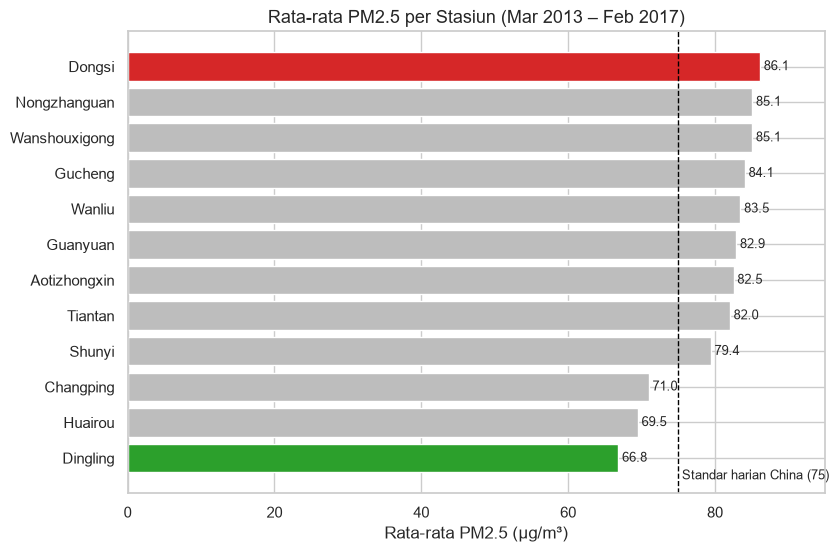

In [18]:
data_q1 = station_pm25["mean"].sort_values()
colors = ["#d62728" if s == data_q1.idxmax() else "#2ca02c" if s == data_q1.idxmin() else "#bdbdbd"
          for s in data_q1.index]

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(data_q1.index, data_q1.values, color=colors)
ax.axvline(75, color="black", linestyle="--", linewidth=1)
ax.text(75.5, -0.6, "Standar harian China (75)", fontsize=9)
for i, v in enumerate(data_q1.values):
    ax.text(v + 0.5, i, f"{v:.1f}", va="center", fontsize=9)
ax.set_title("Rata-rata PM2.5 per Stasiun (Mar 2013 – Feb 2017)", fontsize=13)
ax.set_xlabel("Rata-rata PM2.5 (µg/m³)")
ax.set_ylabel(None)
ax.set_xlim(0, 95)
plt.show()

**Insight:**
- **Dongsi** (merah) memiliki rata-rata PM2.5 tertinggi yaitu **86,14 µg/m³**, sedangkan **Dingling** (hijau) terendah yaitu **66,85 µg/m³**. Selisihnya **19,30 µg/m³** (sekitar 29%).
- 9 dari 12 stasiun berada di atas standar harian 75 µg/m³. Hanya stasiun pinggiran utara (Changping, Huairou, Dingling) yang di bawahnya.

### Pertanyaan 2: Pada musim dan bulan apa rata-rata PM2.5 tertinggi (Mar 2013 – Feb 2017)?

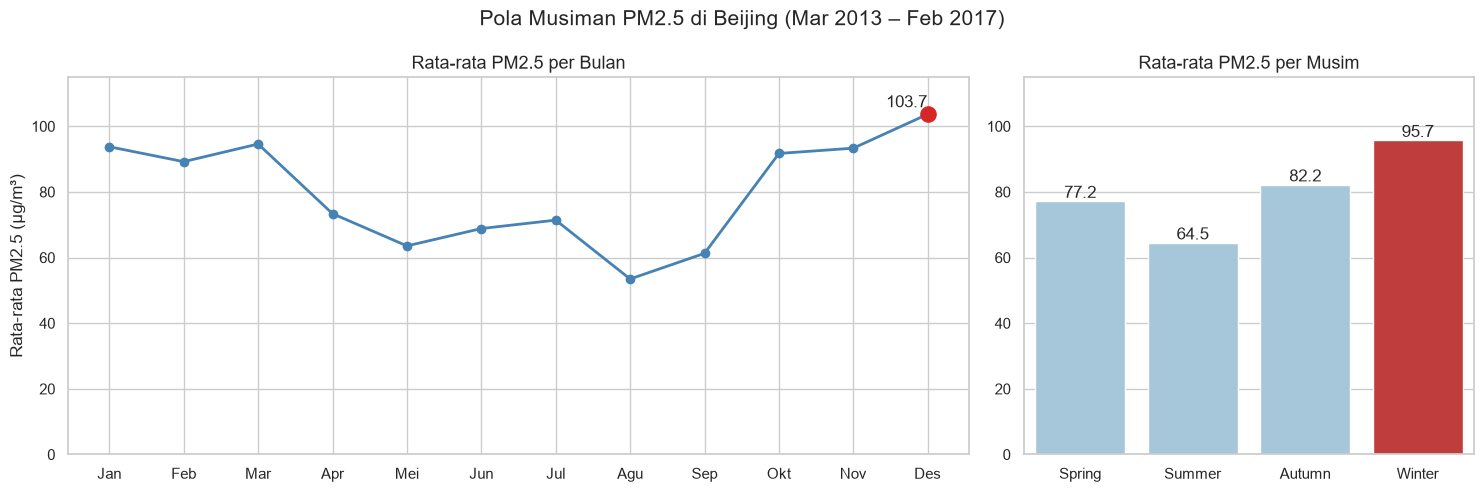

In [19]:
season_colors = {"Spring": "#9ecae1", "Summer": "#9ecae1", "Autumn": "#9ecae1", "Winter": "#d62728"}
month_names = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [2, 1]})

axes[0].plot(month_names, monthly_pm25.values, marker="o", color="steelblue", linewidth=2)
axes[0].scatter(month_names[monthly_pm25.idxmax() - 1], monthly_pm25.max(), color="#d62728", s=120, zorder=3)
axes[0].annotate(f"{monthly_pm25.max():.1f}", (monthly_pm25.idxmax() - 1, monthly_pm25.max()),
                 textcoords="offset points", xytext=(-30, 5))
axes[0].set_title("Rata-rata PM2.5 per Bulan", fontsize=13)
axes[0].set_ylabel("Rata-rata PM2.5 (µg/m³)")
axes[0].set_ylim(0, 115)

sns.barplot(x=season_pm25.index, y=season_pm25.values, hue=season_pm25.index,
            palette=season_colors, legend=False, ax=axes[1])
for i, v in enumerate(season_pm25.values):
    axes[1].text(i, v + 1, f"{v:.1f}", ha="center")
axes[1].set_title("Rata-rata PM2.5 per Musim", fontsize=13)
axes[1].set_xlabel(None)
axes[1].set_ylabel(None)
axes[1].set_ylim(0, 115)

fig.suptitle("Pola Musiman PM2.5 di Beijing (Mar 2013 – Feb 2017)", fontsize=15)
plt.tight_layout()
plt.show()

**Insight:**
- PM2.5 membentuk pola "U": tinggi di akhir tahun hingga awal tahun, terendah di bulan Agustus (53,5 µg/m³).
- **Winter** (Des–Feb) adalah musim terburuk dengan rata-rata **95,74 µg/m³**, **48,4% lebih tinggi** dibanding Summer (64,52 µg/m³). **Desember** adalah bulan dengan rata-rata tertinggi (**103,68 µg/m³**).
- Hal ini sejalan dengan musim pemanas ruangan berbahan bakar batu bara dan kondisi udara yang lebih stagnan di musim dingin.

## Analisis Lanjutan: Clustering dengan Binning Kategori Kualitas Udara

**Tujuan:** mengelompokkan setiap hari di setiap stasiun ke dalam kategori kualitas udara berdasarkan rata-rata PM2.5 harian, menggunakan teknik **binning** (tanpa machine learning). Batas kategori mengikuti standar AQI China (HJ 633-2012) untuk PM2.5 24 jam:

| Kategori | PM2.5 (µg/m³) |
|---|---|
| Baik | 0 – 35 |
| Sedang | 35 – 75 |
| Tidak Sehat (Sensitif) | 75 – 115 |
| Tidak Sehat | 115 – 150 |
| Sangat Tidak Sehat | 150 – 250 |
| Berbahaya | > 250 |

Dengan pengelompokan ini, terlihat berapa persen hari yang berbahaya bagi kesehatan, bukan hanya rata-ratanya.

In [20]:
daily = (df.set_index("datetime")
           .groupby("station")[["PM2.5", "PM10", "SO2", "NO2", "CO", "O3", "TEMP", "WSPM"]]
           .resample("D").mean()
           .reset_index())
daily["season"] = daily["datetime"].dt.month.map(season_map)

aqi_labels = ["Baik", "Sedang", "Tidak Sehat (Sensitif)", "Tidak Sehat", "Sangat Tidak Sehat", "Berbahaya"]
daily["aqi_category"] = pd.cut(daily["PM2.5"], bins=[0, 35, 75, 115, 150, 250, float("inf")],
                               labels=aqi_labels, include_lowest=True)

(daily["aqi_category"].value_counts(normalize=True).reindex(aqi_labels) * 100).round(1)

aqi_category
Baik                      29.5
Sedang                    30.1
Tidak Sehat (Sensitif)    18.2
Tidak Sehat                9.5
Sangat Tidak Sehat         9.2
Berbahaya                  3.4
Name: proportion, dtype: float64

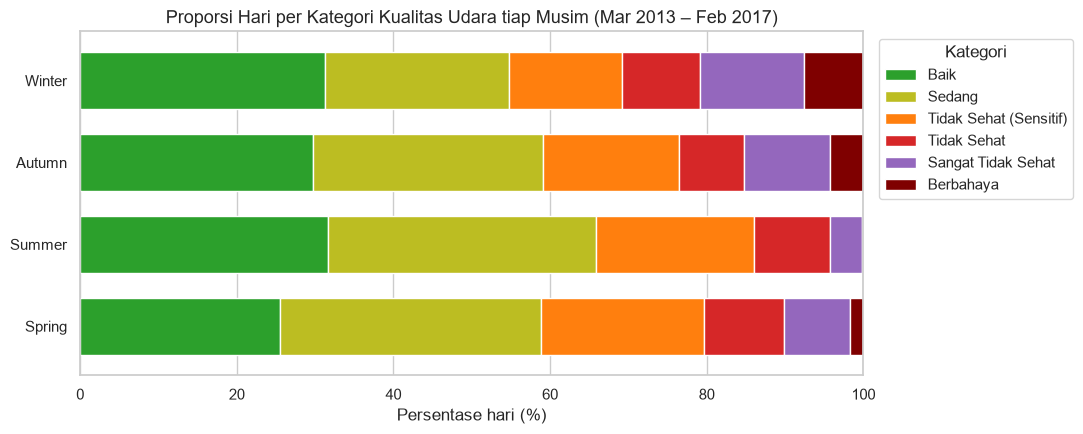

In [21]:
season_cat = pd.crosstab(daily["season"], daily["aqi_category"], normalize="index").reindex(season_order) * 100
aqi_colors = ["#2ca02c", "#bcbd22", "#ff7f0e", "#d62728", "#9467bd", "#7f0000"]

ax = season_cat.plot(kind="barh", stacked=True, color=aqi_colors, figsize=(11, 4.5), width=0.7)
ax.set_title("Proporsi Hari per Kategori Kualitas Udara tiap Musim (Mar 2013 – Feb 2017)", fontsize=13)
ax.set_xlabel("Persentase hari (%)")
ax.set_ylabel(None)
ax.set_xlim(0, 100)
ax.legend(title="Kategori", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Insight:**
- Hanya sekitar **30%** hari yang masuk kategori "Baik"; sekitar **40%** hari masuk kategori tidak sehat atau lebih buruk.
- Winter memiliki porsi hari "Berbahaya" paling besar (~7,5%) dan "Sangat Tidak Sehat" (~13%), sedangkan di Summer hari "Berbahaya" hampir tidak ada (~0,2%).
- Menariknya, porsi hari "Baik" di Winter tidak lebih kecil dari musim lain: kualitas udara musim dingin sangat fluktuatif (hari berangin bersih, hari stagnan sangat buruk).

### Menyimpan data untuk dashboard

In [22]:
daily.to_csv("dashboard/main_data.csv", index=False)
daily.shape

(17532, 12)

## Simpulan

- **Simpulan Pertanyaan 1:** Selama Maret 2013 – Februari 2017, stasiun **Dongsi** memiliki rata-rata PM2.5 tertinggi (**86,14 µg/m³**) dan **Dingling** terendah (**66,85 µg/m³**), dengan selisih **19,30 µg/m³**. Polusi terkonsentrasi di stasiun pusat kota. 9 dari 12 stasiun melebihi standar harian China (75 µg/m³).
- **Simpulan Pertanyaan 2:** **Winter** (Des–Feb) adalah musim dengan rata-rata PM2.5 tertinggi (**95,74 µg/m³**), **48,4% lebih tinggi** daripada Summer (64,52 µg/m³), dan **Desember** adalah bulan terburuk (**103,68 µg/m³**). Winter juga memiliki porsi hari berkategori "Berbahaya" terbesar.

### Rekomendasi (Action Item)
1. **Memprioritaskan pengendalian emisi di stasiun pusat kota** (Dongsi, Nongzhanguan, Wanshouxigong), misal: pembatasan kendaraan dan pengawasan sumber emisi lokal, karena wilayah ini konsisten paling tercemar.
2. **Terapkan kebijakan musiman mulai November hingga Februari**: percepat peralihan pemanas batu bara ke gas/listrik, aktifkan sistem peringatan dini polusi, dan imbau warga (terutama kelompok sensitif) membatasi aktivitas luar ruangan pada hari berkategori "Sangat Tidak Sehat"/"Berbahaya".